# AP 155 Lab Exercise
---
## Exercise 10: Fourier transform

_Instructions_:
- **Report**: See instructions in Problems 1,2,3
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Lagat, Elijah Manuel T.
- _Student No._: 2024-15681
- _Section_: WX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

<img src="dirac_delta.png" alt="Alt text" width=75%> 

For the dirac delta, its Fourier transform is seen to be a constant with magnitude 1, which represents having every frequency present. The Dirac Delta
is represented in python as a Gaussian function with the sigma parameter approaching zero to minimize the curve width and emulating a sharp spike reaching infinity at zero. Varying the sigma variable changes the fourier transform by making it more narrow, which means that less frequencies are 
present in the transform. in the extreme case where the sigma approaches infinity, the Gaussian would look like a constant, which will mean it has exactly zero frequency, leading to a Dirac delta representation in its Fourier transform centered at zero. This shows the inverse relation between the Gaussian sigma variable and its Fourier transform. Trigonometric functions would also be Dirac delta functions but will be centered at non-zero frequencies. This shows the characteristic frequency of the sine or cosine signal.

<img src="noisy_sig.png" alt="Alt text" width=75%> 

Reducing N lessens the sampling density, which lowers frequency resolution and results in blurry peaks. If N is too low, adding noise will make it difficult to discern the actual signal, making it impossible to accurately recover the original frequency from the noise floor. There is a defined limit dictated by the Nyquist theorem , which requires ($\Delta f = 1/T$), below which the signal cannot be properly resolved.

The process of recovering a clean signal from a noisy signal is through the use of the Hanning window and filtering the resulting signal by only letting select frequencies through a threshold based on magnitude. The Hanning window, when multiplied to the noisy signal, isolates the middle frequencies to make it easier to perform the fast Fourier transform and circumvent the coding error that results in a blurry signal.

<img src="anti_alias.png" alt="Alt text" width=75%> 

The target signal is properly sampled at a high frequency of $f_s = 100.0\text{ Hz}$, which exceeds the Nyquist frequency ($f_s > 2 f = 10\text{ Hz}$) and accurately represents the shape of the waveform. In contrast, the middle panel shows the wave under-sampled at $f_s = 7.0\text{ Hz}$, severely distorting the signal and causing it to appear as a lower-frequency oscillation. As demonstrated in the bottom Fourier transform comparison, proper sampling resolves the genuine spectral peaks at $\pm 5\text{ Hz}$, whereas under-sampling produces false aliased peaks (aliasing artifacts) at incorrect lower frequencies, showing how insufficient sampling frequency causes high-frequency information to masquerade as lower frequencies.   

EDIT ME. See instruction above for what to include. Insert caption here, a short description what the figure illustrates. The syntax in markdown for putting a figure is `![Description](local_file_name.png)` or `<img src="/path/to_image.jpg" alt="Alt text" width=45%>`. Make sure the figure has complete elements.


### Report discussion

EDIT ME. See instruction above for what to include. Insert your discussions here. Discuss your key results with at most 150 words per question.

### Other comments
- EDIT ME
- A self reflection can be placed here.
- This portion is not graded.
- You may insert further questions here.


---
## Section 2: Code

In [133]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Exploring FT of varying waveforms

Given the waveforms from the pool below, produce a $1\times3$ plot containing the following: 
1) the signal, with its variations, 
2) the magnitude of its Fourier transform, and 
3) the phase information of the transform (up to you if unwrapped or not). 
    
Discussion: 2-3 sentences explaining how changing the shape of the input signal affects it transform. 
Ex: for the Gaussian waveform, how does it Fourier transform change based on increasing or decreasing sigma?

Waveforms you can try (prefarably non-sinusoidal):
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function (vary sigma)
- Finite-time sinusoid
- Gaussian wave packet
- Dirac-delta 

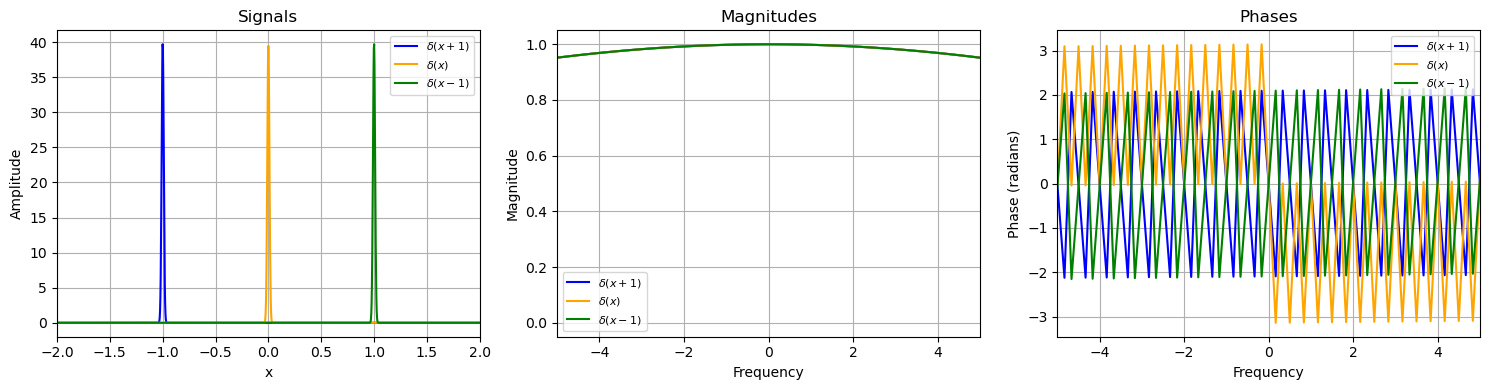

In [134]:

N = 2000
x = np.linspace(-3, 3, N)


def dirac_delta(x, x0, sigma=0.01): # Dirac Delta Function
  return (1.0 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
      -((x - x0) ** 2) / (2 * sigma**2)
  )


# Defining Dirac deltas at different centers
delta_l = dirac_delta(x, -1.0)  
delta_c = dirac_delta(x, 0.0) 
delta_r = dirac_delta(x, 1.0)  

deltaT = x[1] - x[0] # step size of change in x
freqs = np.fft.fftshift(np.fft.fftfreq(N, deltaT)) # create the array of sample frequencies to be use by the fast fourier transform. 
# fftshift is to center


fft_l = np.fft.fftshift(np.fft.fft(delta_l)) * deltaT # perform fft on the functions
fft_c = np.fft.fftshift(np.fft.fft(delta_c)) * deltaT
fft_r = np.fft.fftshift(np.fft.fft(delta_r)) * deltaT


mag_l, phase_left = np.abs(fft_l), np.angle(fft_l) # obtain magnitude and angle arrays
mag_c, phase_center = np.abs(fft_c), np.angle(fft_c)
mag_r, phase_right = np.abs(fft_r), np.angle(fft_r)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))


axs[0].plot(x, delta_left, label="$\delta(x + 1)$", color="blue", linestyle="-")
axs[0].plot(
    x, delta_center, label="$\delta(x)$", color="orange", linestyle="-"
)
axs[0].plot(
    x, delta_right, label="$\delta(x - 1)$", color="green", linestyle="-"
)
axs[0].set_title("Signals")
axs[0].set_xlabel("x")
axs[0].set_ylabel("Amplitude")
axs[0].legend(fontsize=8)
axs[0].grid(True)
axs[0].set_xlim(-2, 2)


axs[1].plot(freqs, mag_left, label="$\delta(x+1)$", color="blue", linestyle="-")
axs[1].plot(
    freqs, mag_center, label="$\delta(x)$", color="orange", linestyle="-"
)
axs[1].plot(
    freqs, mag_right, label="$\delta(x-1)$", color="green", linestyle="-"
)
axs[1].set_title("Magnitudes")
axs[1].set_xlabel("Frequency")
axs[1].set_ylabel("Magnitude")
axs[1].legend(fontsize=8)
axs[1].grid(True)
axs[1].set_xlim(-5, 5)


axs[2].plot(
    freqs, phase_left, label="$\delta(x+1)$", color="blue", linestyle="-"
)
axs[2].plot(
    freqs, phase_center, label="$\delta(x)$", color="orange", linestyle="-"
)
axs[2].plot(
    freqs, phase_right, label="$\delta(x-1)$", color="green", linestyle="-"
)
axs[2].set_title("Phases")
axs[2].set_xlabel("Frequency")
axs[2].set_ylabel("Phase (radians)")
axs[2].legend(fontsize=8)
axs[2].grid(True)
axs[2].set_xlim(-5, 5)


plt.savefig('dirac_delta', dpi=300)
plt.tight_layout()
plt.show()

### Problem 2: Signal Processing in 1D (Fill in the blanks/Code to get to the desired result)

Steps performed: 

1) Create a composite signal from multiple sinusoids with three frequencies, get fft of clean signal
2) Add noise (gaussian noise)
3) Add a window (Hann)
4) Get fft of the noisy signal
5) filter frequencies below a threshold
6) get the inverse fft
7) compare the result

Discussion: Try running the procedure with a lower number of N (N<25000). What does lowering N do to the original signal? Will I still be able to recover that original signal if I add the noise below? Is there a limit of N to which I can recover the signal well? Why? (Answer in ~3 sentences)


In [135]:
#Make a wave (cosine or sine) - you can do combo of waves
Nw = 25000
dt = 0.0002 #if spacing is 0.0002, then frequency is 5000 Hz 
t_ = np.arange(Nw)*dt
freqs = [130, 230, 180]
phase = [np.pi/3, np.pi/4, np.pi/6]


signal_original = np.sum([np.cos(2*np.pi*f*t_ + p) for f, p in zip(freqs, phase)], axis=0)

(0.0, 0.3)

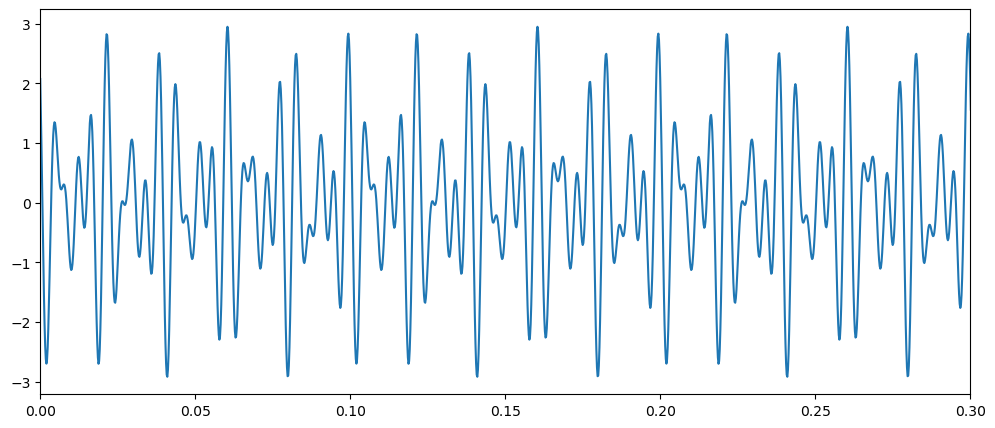

In [136]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, signal_original)
ax.set_xlim(0,0.3)

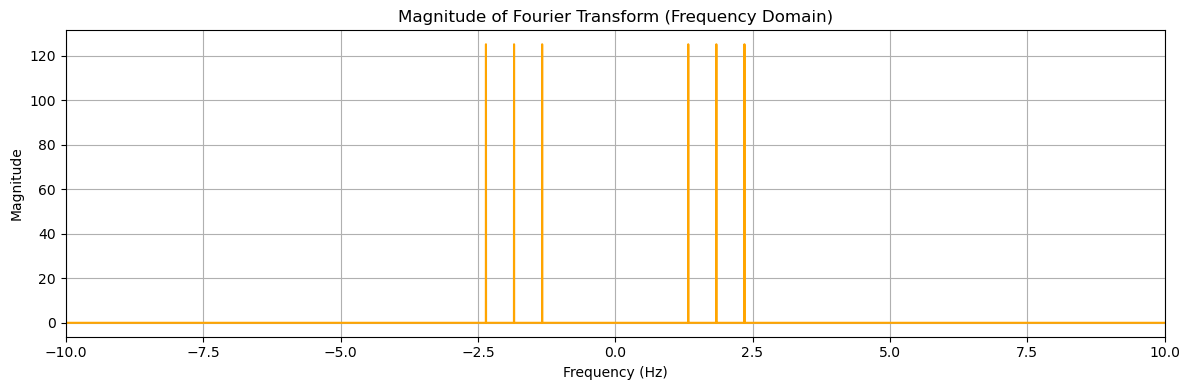

In [137]:
#FILL: Plot the fourier transform of the clean, original signal

# 2. Compute the Fourier Transform & Frequencies
frequencies = np.fft.fftshift(np.fft.fftfreq(Nw, d=dx))
ft_result = np.fft.fftshift(np.fft.fft(signal_original)) * dt

# 3. Plotting
fig, axs = plt.subplots(figsize=(12, 4))

# Magnitude Spectrum
axs.plot(frequencies, magnitude, color="orange")
axs.set_title("Magnitude of Fourier Transform (Frequency Domain)")
axs.set_xlabel("Frequency (Hz)")
axs.set_ylabel("Magnitude")
axs.grid(True)
axs.set_xlim(-10, 10)  

plt.tight_layout()
plt.show()

In [138]:
rng = np.random.default_rng()

#Define parameters of Gaussian noise)
mean = 0
std = 2

noise = rng.normal(loc = mean, scale = std, size = len(t_)) #Add noise to every data point
#Noisy data here
noisy_data = signal_original + noise*5

(0.0, 0.3)

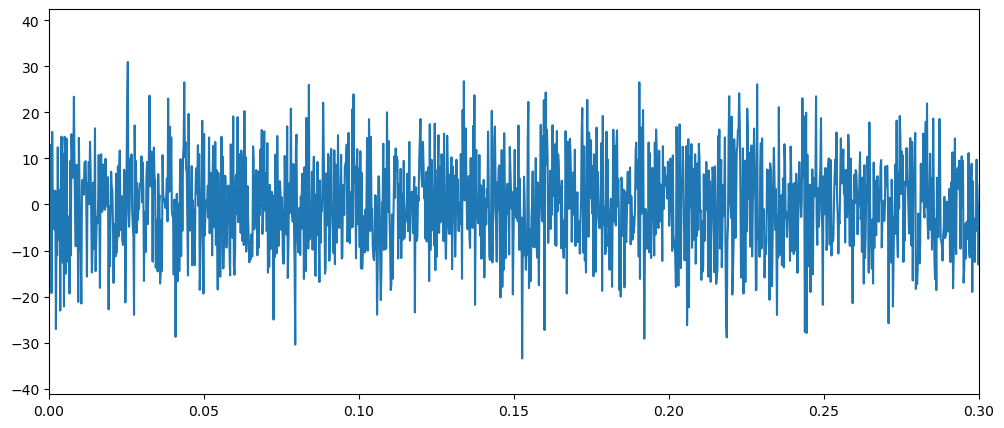

In [139]:
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, noisy_data)
ax.set_xlim(0,0.3)

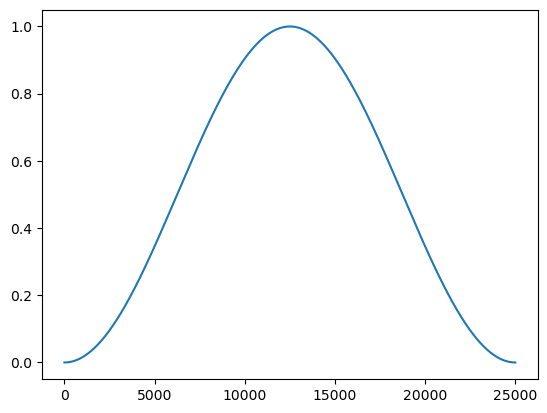

In [140]:
window = np.hanning(len(noisy_data)) #Create a window the size of the data length
plt.plot(window)

In [141]:
#fourier of hanning window
windowSigPeaks = np.abs(np.fft.fftshift(np.fft.fft(window)))
windowSigFreqs = np.fft.fftshift(np.fft.fftfreq(Nw, dt))


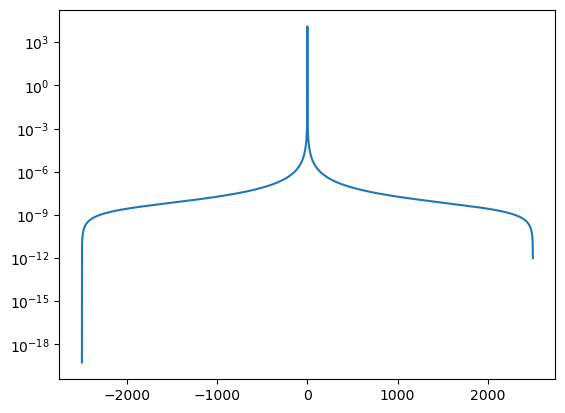

In [142]:
plt.plot(windowSigFreqs, windowSigPeaks)
plt.yscale('log')

In [143]:
noisyFourier = np.fft.fft(noisy_data*window)

noisySigPeaks = np.abs(np.fft.fftshift(np.fft.fft(noisy_data*window)))

# multiplying the noisy signal by the hanning window

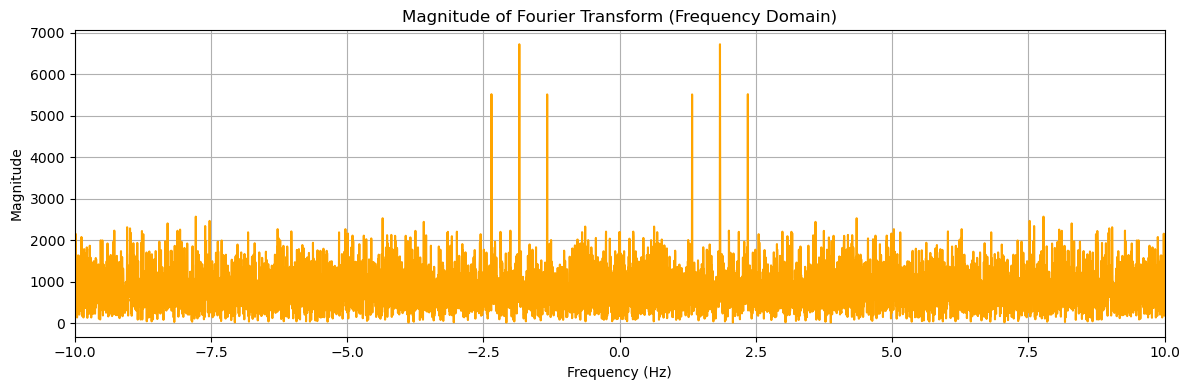

In [155]:
# Fill: Plot the magnitude of fourier transform of the noisy data multiplied by the hanning window
frequencies = np.fft.fftshift(np.fft.fftfreq(Nw, d=dx))


fig, axs = plt.subplots(figsize=(12, 4))


axs.plot(frequencies, noisySigPeaks, color="orange")
axs.set_title("Magnitude of Fourier Transform (Frequency Domain)")
axs.set_xlabel("Frequency (Hz)")
axs.set_ylabel("Magnitude")
axs.grid(True)
axs.set_xlim(-10, 10)  

plt.savefig('noisy_sig', dpi=300)
plt.tight_layout()
plt.show()

# plot of hanning fourier transform


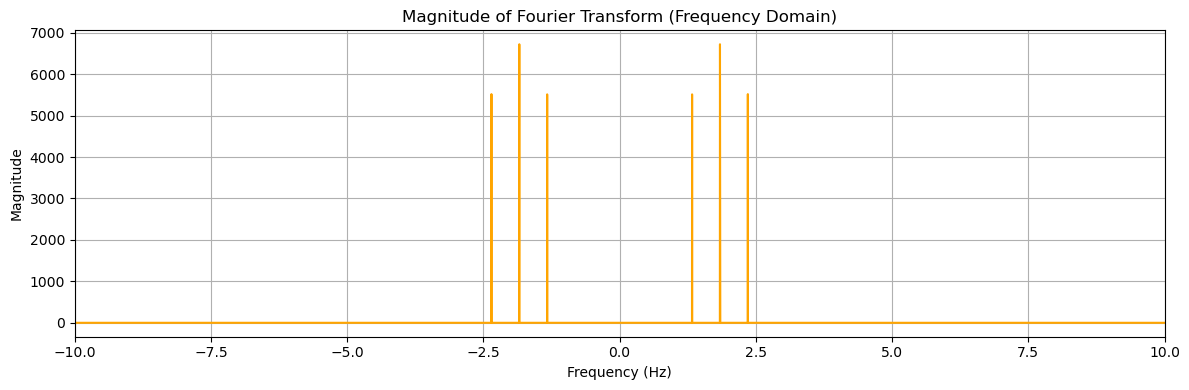

In [145]:
# Fill: Find a suitable threshold value to filter the noise in fourier space
newSigPeaks = noisySigPeaks.copy()
thresh = 0.6 * newSigPeaks.max()

for i in range(len(newSigPeaks)):
  if newSigPeaks[i] < thresh:
    newSigPeaks[i] = 0

fig, axs = plt.subplots(figsize=(12, 4))

axs.plot(frequencies, newSigPeaks, color="orange")
axs.set_title("Magnitude of Fourier Transform (Frequency Domain)")
axs.set_xlabel("Frequency (Hz)")
axs.set_ylabel("Magnitude")
axs.grid(True)
axs.set_xlim(-10, 10)  

plt.tight_layout()
plt.show()

# Remove signals that are less than 60% of maximnum magnitude. Those that remain are the actual frequencies.


In [146]:
# Fill: with the cleaned signal in fourier space, convert it back to the time domain

In [147]:

func_unshifted = np.fft.ifftshift(newSigPeaks)
reco = np.real(np.fft.ifft(func_unshifted))


# recovered inerse fourier transform signal


(0.0, 0.3)

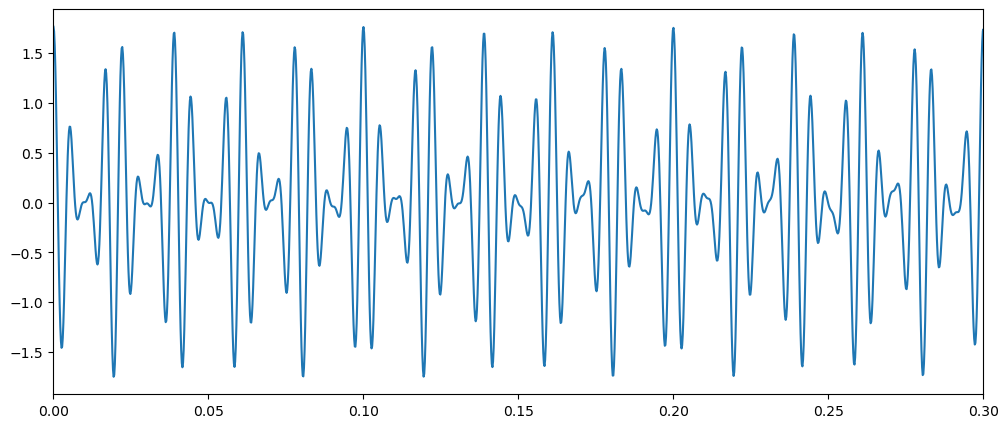

In [148]:
# Plot the recovered signal
fig, ax = plt.subplots(figsize= (12,5))
ax.plot(t_, reco)
ax.set_xlim(0,0.3)

### Problem 3: Aliasing
1) Using different sampling frequencies (uniform sampling), generate a sinusoidal signal. Note the sampling frequencies, and the signal frequency. Use a sampling frequency above the Nyquist frequency, and another one below it.
3) Get their fourier transforms. Are they the same?
4) Plot: Show the fourier transform of an aliased signal, how it looks like in the time-domain, and how the actual signal looks like in the time domain if it's not aliased.
   
Discussion: Explain the report figure. Note the frequency of the signal you wanted to sample, the sampling frequencies used for the aliased and the non-aliased wave

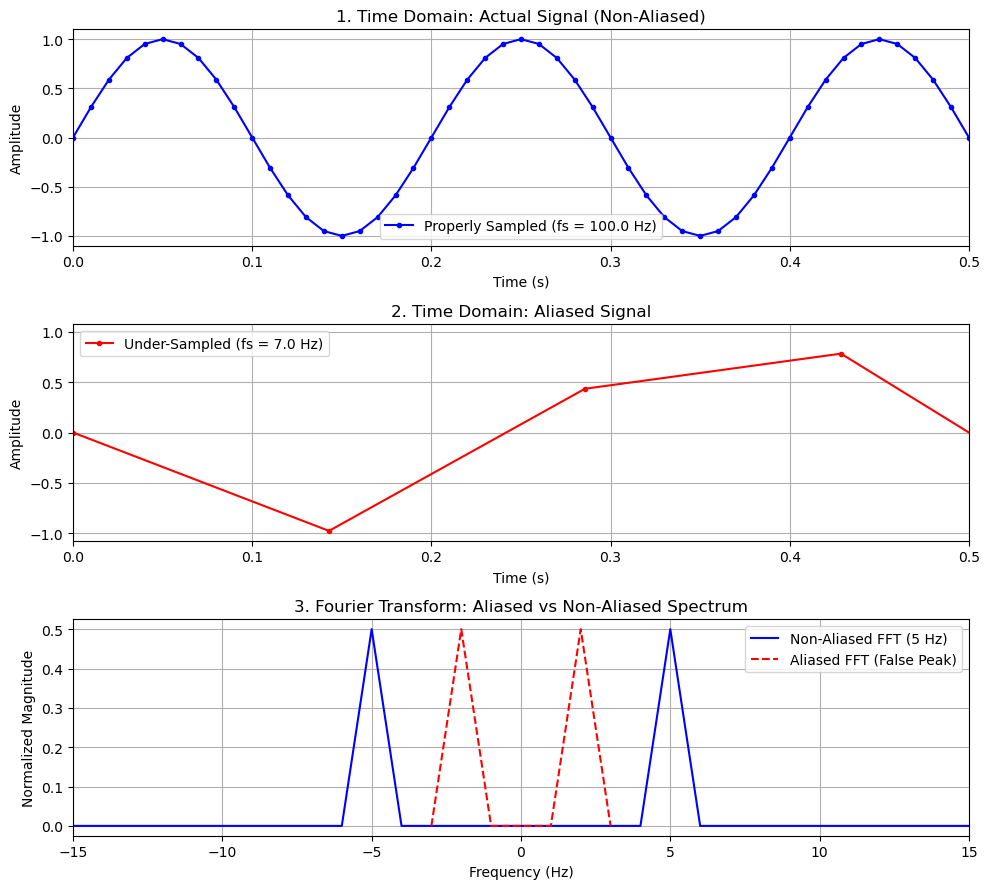

In [154]:
# actual signal frequency
f_signal = 5.0  
duration = 1.0  

# high sampling rate
fs_high = 100.0
t_high = np.arange(0, duration, 1 / fs_high)
signal_high = np.sin(2 * np.pi * f_signal * t_high)

# low sampling rate
fs_low = 7.0
t_low = np.arange(0, duration, 1 / fs_low)
signal_low = np.sin(2 * np.pi * f_signal * t_low)


fft_high = np.fft.fftshift(np.fft.fft(signal_high))
freqs_high = np.fft.fftshift(np.fft.fftfreq(len(signal_high), d=1 / fs_high))
mag_high = np.abs(fft_high)


fft_low = np.fft.fftshift(np.fft.fft(signal_low))
freqs_low = np.fft.fftshift(np.fft.fftfreq(len(signal_low), d=1 / fs_low))
mag_low = np.abs(fft_low)


fig, axs = plt.subplots(3, 1, figsize=(10, 9))


axs[0].plot(
    t_high, signal_high, "b.-", label=f"Properly Sampled (fs = {fs_high} Hz)"
)
axs[0].set_title("1. Time Domain: Actual Signal (Non-Aliased)")
axs[0].set_xlabel("Time (s)")
axs[0].set_ylabel("Amplitude")
axs[0].grid(True)
axs[0].legend()
axs[0].set_xlim(0, 0.5)


axs[1].plot(t_low, signal_low, "r.-", label=f"Under-Sampled (fs = {fs_low} Hz)")
axs[1].set_title("2. Time Domain: Aliased Signal")
axs[1].set_xlabel("Time (s)")
axs[1].set_ylabel("Amplitude")
axs[1].grid(True)
axs[1].legend()
axs[1].set_xlim(0, 0.5)


axs[2].plot(
    freqs_high, mag_high / len(signal_high), "b", label="Non-Aliased FFT (5 Hz)"
)
axs[2].plot(
    freqs_low,
    mag_low / len(signal_low),
    "r--",
    label="Aliased FFT (False Peak)",
)
axs[2].set_title("3. Fourier Transform: Aliased vs Non-Aliased Spectrum")
axs[2].set_xlabel("Frequency (Hz)")
axs[2].set_ylabel("Normalized Magnitude")
axs[2].grid(True)
axs[2].set_xlim(-15, 15)
axs[2].legend()

plt.savefig('anti_alias', dpi=300)
plt.tight_layout()
plt.show()


#### Problem code summary

Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---
## Section 3: Notes

In [15]:
import numpy as np
import matplotlib.pyplot as plt

### Fourier transform (from $t$-space to $\omega$-space)
$$ Y(\omega) = \int_{-\infty}^{+\infty} dt \frac{e^{-i\omega t}}{\sqrt{2\pi}}y(t)$$

### Inverse Fourier transform (from $\omega$-space to $t$-space)
$$ y(t) = \int_{-\infty}^{+\infty} d\omega Y(\omega) \frac{e^{i\omega t}}{\sqrt{2\pi}}$$

Something to think about: while we essentially do numerical integration, we do not impose h. Instead, we utilize the spacing of the dataset.

### Discrete FT/IFT

$$ Y_n = \frac{1}{\sqrt{2\pi}} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{y_k\}  +\sin(nk\theta)\Im\{y_k\} +i(\cos(nk\theta)\Im\{y_k\} −\sin(nk\theta)\Re\{y_k\})]\right]$$

$$ y_k = \frac{\sqrt{2\pi}}{N} \sum_{k=1}^N \left[(\cos(nk\theta)\Re\{Y_n\}  -\sin(nk\theta)\Im\{Y_n\} +i(\cos(nk\theta)\Im\{Y_n\} +\sin(nk\theta)\Re\{Y_n\})]\right]$$

Why bother it doing this way? 

It cleanly splits the real and imaginary part for both inputs and outputs, so that you can use a pair of floats rather than an aggregate complex data type (complex128 is just a pair of float64 anyway).

Using $Z=e^{−i\theta}, \rightarrow Z^{\pm nk} = e^{\mp ink\theta} = \cos(nk\theta)\mp i\sin(nk\theta)$.

(0.0, 4.0)

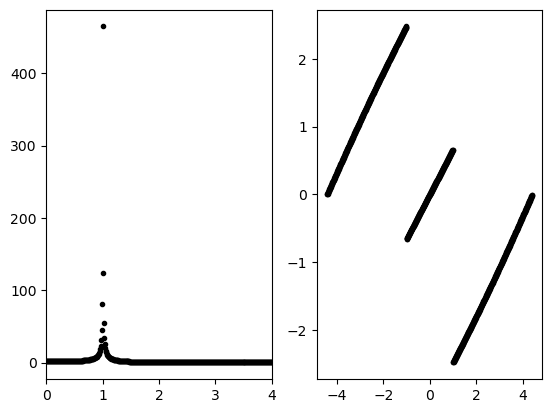

In [16]:
import numpy as np
import matplotlib.pyplot as plt

N = 1000
x = np.linspace(0, 18*2*np.pi, N)
deltaT = x[1] - x[0]

f = 1
y = np.cos(2*np.pi*f*x)

freqs = np.fft.fftfreq(N, deltaT)
Yk = np.fft.fft(y)

# # Q: Why do fftshift?
# Yk = np.fft.fftshift(Yk)

Yk_mag = np.abs(Yk)
Yk_phase = np.angle(Yk)
# Q: Why unwrap?
Yk_phase = np.unwrap(Yk_phase)

fig, ax = plt.subplots(1,2)

ax[0].plot(freqs, Yk_mag, "k.")
ax[1].plot(freqs, Yk_phase, "k.")
ax[0].set_xlim(0, 4)

### Waveforms of interest
- Sinusoid (single frequency, varying phase shift)
- Sum of sinusoids with different frequencies and phases
- Product of sinusoids with different frequencies and phases
- Square wave (both single and periodic)
- Triangle wave (sawtooth, ramp, reverse ramp)
- Gaussian function
- Finite-time sinusoid
- Gaussian wave packet

In [17]:
t = np.linspace(0,10,1000) #Create 100 pts from 0 to 10
x = np.sin(2*np.pi*2*t)

Text(0, 0.5, 'x')

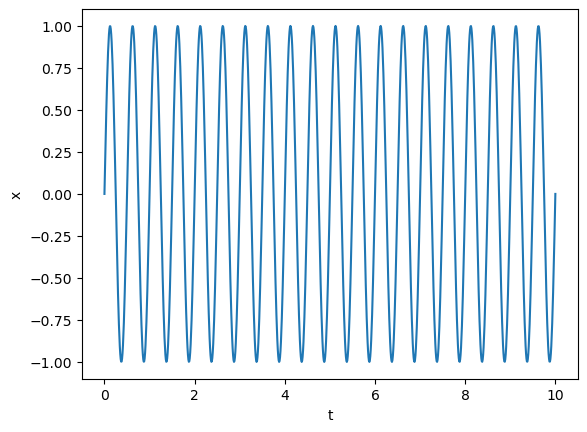

In [18]:
plt.plot(t,x)
plt.xlabel("t")
plt.ylabel("x")

In [19]:
x_ft = np.fft.fft(x)
np.fft.fftfreq?

Signature: np.fft.fftfreq(n, d=1.0)
Docstring:
Return the Discrete Fourier Transform sample frequencies.

The returned float array `f` contains the frequency bin centers in cycles
per unit of the sample spacing (with zero at the start).  For instance, if
the sample spacing is in seconds, then the frequency unit is cycles/second.

Given a window length `n` and a sample spacing `d`::

  f = [0, 1, ...,   n/2-1,     -n/2, ..., -1] / (d*n)   if n is even
  f = [0, 1, ..., (n-1)/2, -(n-1)/2, ..., -1] / (d*n)   if n is odd

Parameters
----------
n : int
    Window length.
d : scalar, optional
    Sample spacing (inverse of the sampling rate). Defaults to 1.

Returns
-------
f : ndarray
    Array of length `n` containing the sample frequencies.

Examples
--------
>>> signal = np.array([-2, 8, 6, 4, 1, 0, 3, 5], dtype=float)
>>> fourier = np.fft.fft(signal)
>>> n = signal.size
>>> timestep = 0.1
>>> freq = np.fft.fftfreq(n, d=timestep)
>>> freq
array([ 0.  ,  1.25,  2.5 , ..., -3.75, -2.5 , -1

### Plotting

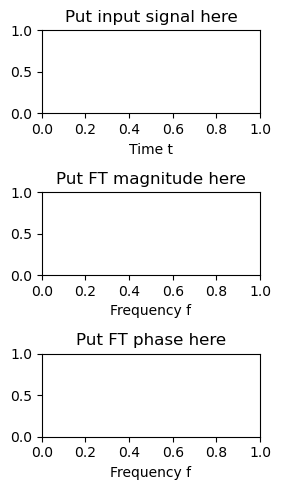

In [20]:
fig, ax = plt.subplots(3, 1, figsize=(3, 5))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

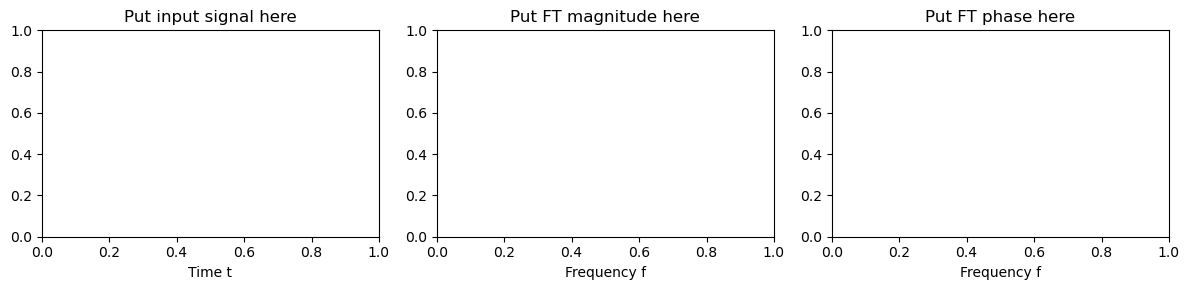

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3))

ax[0].set_title("Put input signal here")
ax[0].set_xlabel("Time t")
#....
ax[1].set_title("Put FT magnitude here")
ax[1].set_xlabel("Frequency f")
#....
ax[2].set_title("Put FT phase here")
ax[2].set_xlabel("Frequency f")
#...

fig.tight_layout()

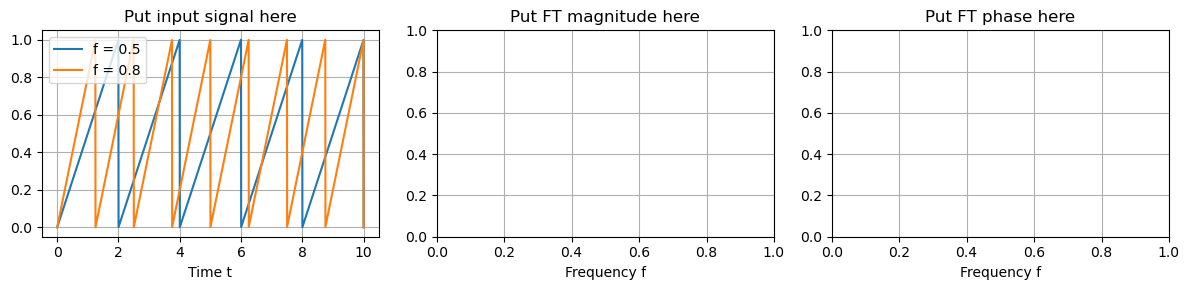

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(12, 3))
ax_t, ax_f, ax_p = axs

t = np.linspace(0, 10, 2048)
f = 0.5 # Frequency
T = 1/(f) # Period
f2 = 0.8 # Frequency
T2 = 1/(f2) # Period


ax_t.set_title("Put input signal here")
ax_t.set_xlabel("Time t")
ax_t.plot(t, (t%T)/T, label="f = 0.5")
ax_t.plot(t, (t%T2)/T2, label="f = 0.8")
ax_t.legend()
#....
ax_f.set_title("Put FT magnitude here")
ax_f.set_xlabel("Frequency f")
#....
ax_p.set_title("Put FT phase here")
ax_p.set_xlabel("Frequency f")
#...


for ax in axs:
    ax.grid(True)
fig.tight_layout()

## 1-D convolution

In [23]:
a = [1,1,1,0,0,0,0,1,1,1,0,0,0,1,0,0,0,1,1,1,0,1,1,0,0,0,0]
v = [1,1,1]



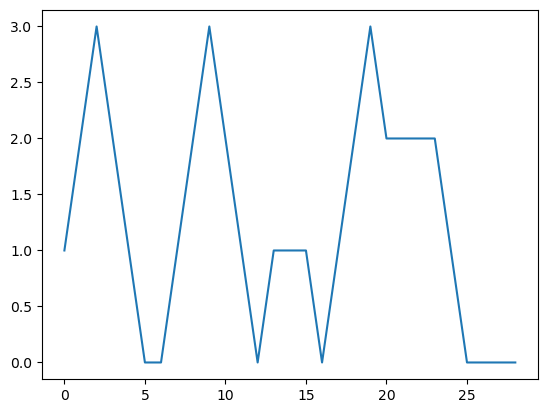

In [24]:
plt.plot(np.arange(len(np.convolve(a,v, mode='full'))), np.convolve(a,v, mode='full'))

### Convolution attempt (bringing circuits analogy) 

In [18]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt
N = 500
t = np.linspace(0, 1, N, endpoint=False)
t_input = np.linspace(0, 5, N*5, endpoint=False)
signal_freq = 5
# dt = t[1] - t[0]
# nonsinu_signal = signal.square(2 * np.pi * signal_freq * t)

In [19]:
tau = 0.1
h_t = np.exp(-t/tau)
input_signal = signal.square(2 * np.pi * signal_freq * t_input) #cont_signal(t, freq)

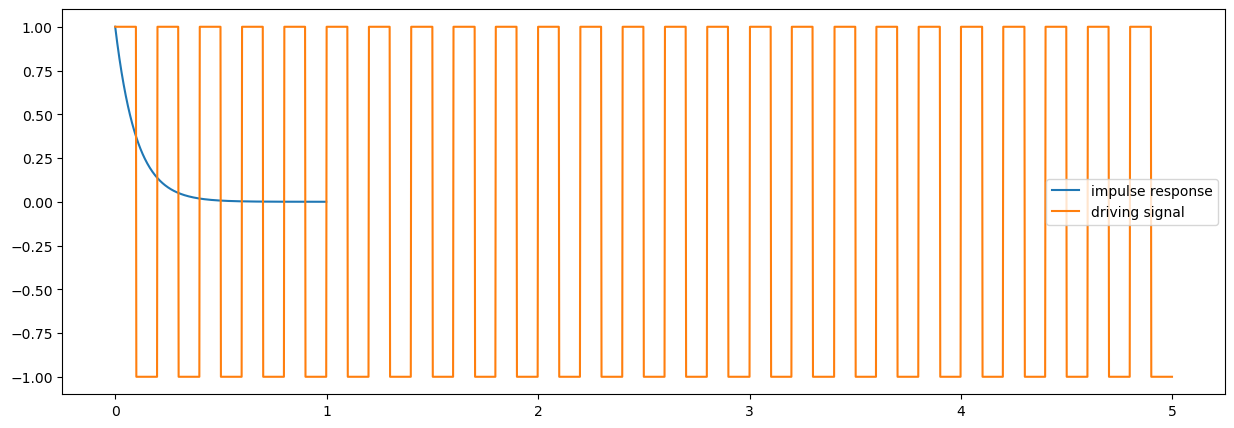

In [20]:
fig, ax = plt.subplots(figsize = (15,5))
ax.plot(t, h_t, label = "impulse response")
ax.plot(t_input, input_signal, label= "driving signal")
ax.legend()

In [21]:
response = np.convolve(input_signal, h_t, mode = "same")

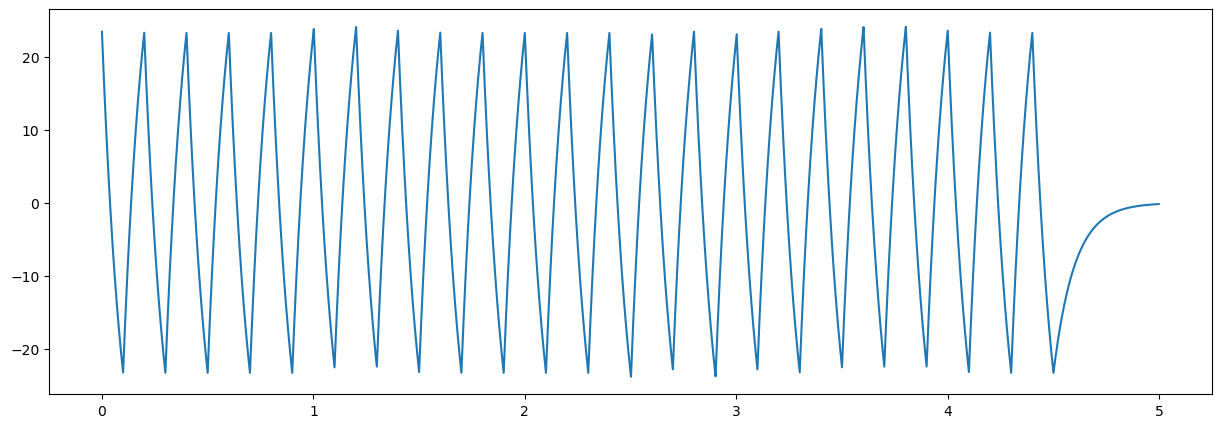

In [22]:
fig, ax = plt.subplots(figsize = (15,5))
#ax.plot(t, input_signal)
ax.plot(t_input, response)

In [23]:
fourier_length = len(h_t) + len(input_signal) - 1

In [24]:
fourier_input = np.fft.fft(input_signal, n = fourier_length)
fourier_h = np.fft.fft(h_t, n = fourier_length)

In [25]:
fourier_response = fourier_h*fourier_input 

In [26]:
response = np.real(np.fft.ifft(fourier_response))

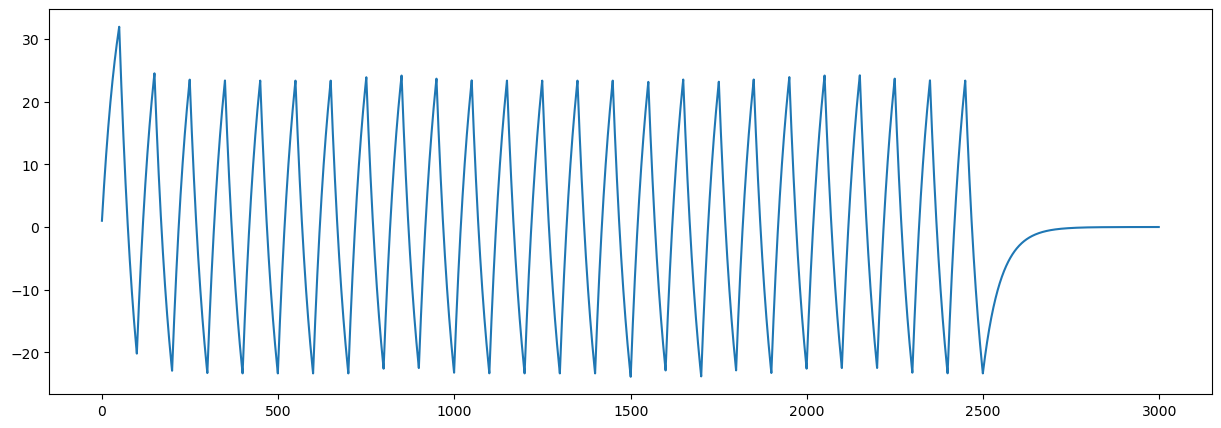

In [27]:
fig, ax = plt.subplots(figsize = (15,5))

ax.plot(response)